# 05 Results: all models, all tasks, train / val / test

Adds the two reference scorers on the same folds, then puts every model side by side:
- **Random**: random scores, chance level
- **Popularity**: score = how many training rows link to the column (for C-T, how many training compounds hit the target;
  for H-C, how many training herbs contain the compound). It ignores the row completely, so a model is only useful if it beats it.

Reads: `prep/`, `results/metrics_rgcn.csv`, `results/metrics_inductive.csv`
Writes: `results/metrics_baselines.csv`, `results/summary_<task>.csv`, `results/summary_test.csv`, `results/test_metrics.png`

## Setup

In [1]:
import hti
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hti.data import Prep, RESULTS, TASKS, TASK_NAMES, kind_of
from hti.metrics import evaluate
from hti.models import popularity_scores, random_scores

prep = Prep()
COLS = ['PR-AUC', 'Hits@10', 'Hits@50', 'MRR', 'loss', 'HT PR-AUC', 'HT Hits@10', 'HT Hits@50', 'HT MRR',
        'HT PR-AUC (model only)', 'HT Hits@10 (model only)', 'HT Hits@50 (model only)', 'HT MRR (model only)']

## Random and popularity on every fold

In [2]:
records = []
for task in TASKS:
    kind = kind_of(task)
    n_rows, n_cols = (prep.n_compounds, prep.n_targets) if kind == 'ct' else (prep.n_herbs, prep.n_compounds)
    for k in range(prep.k):
        fold = prep.fold(task, k)
        for name, scores in [('Random', random_scores(n_rows, n_cols, 1000 + k, prep.device)),
                             ('Popularity', popularity_scores(fold['train']['pos'], n_rows, n_cols, k))]:
            for part, m in evaluate(scores, fold, prep, kind, with_loss=False, herb_popularity=False).items():
                records.append({'task': task, 'model': name, 'fold': k, 'set': part, **m})
baselines = pd.DataFrame(records)
baselines.to_csv(RESULTS / 'metrics_baselines.csv', index=False)
print(len(baselines), 'rows')

120 rows


## All results together

In [3]:
frames = [baselines]
for f in ['metrics_rgcn.csv', 'metrics_inductive.csv']:
    if (RESULTS / f).exists():
        frames.append(pd.read_csv(RESULTS / f))
    else:
        print(f'{f} not found, run the notebook that writes it first')
everything = pd.concat(frames, ignore_index=True)
ORDER = ['Random', 'Popularity', 'R-GCN', 'R-GCN + fixes', 'kNN', 'Two-tower (AAC)', 'Two-tower (ESM-2)', 'Ensemble']


def summary(task, part=None):
    d = everything[everything.task == task]
    if part:
        d = d[d.set == part]
    g = d.groupby(['model', 'set'])[COLS]
    t = (g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)).replace('nan ± nan', '')
    t = t.loc[:, (g.mean().notna().any())]
    models = [m for m in ORDER if m in t.index.get_level_values(0)]
    sets = [s for s in ['train', 'val', 'test'] if s in t.index.get_level_values(1)]
    return t.reindex(pd.MultiIndex.from_product([models, sets], names=['model', 'set'])).dropna(how='all')


for task in TASKS:
    summary(task).to_csv(RESULTS / f'summary_{task}.csv')

## C-T, hidden links (known compounds)
H-T columns are the herb-target pairs reachable only through that part's links.

In [4]:
summary('ct_edge')

PR-AUC        Hits@10        Hits@50  \
model             set                                                  
Random            train  0.091 ± 0.001  0.008 ± 0.001   0.04 ± 0.002   
                  val     0.09 ± 0.003  0.009 ± 0.001  0.041 ± 0.005   
                  test    0.02 ± 0.001  0.009 ± 0.001  0.042 ± 0.003   
Popularity        train   0.38 ± 0.003   0.16 ± 0.004  0.441 ± 0.005   
                  val    0.363 ± 0.008  0.151 ± 0.008  0.422 ± 0.009   
                  test   0.113 ± 0.004  0.153 ± 0.007   0.42 ± 0.009   
R-GCN             train  0.626 ± 0.055   0.74 ± 0.038  0.939 ± 0.015   
                  val    0.421 ± 0.029  0.442 ± 0.017  0.673 ± 0.015   
                  test   0.135 ± 0.016  0.446 ± 0.004  0.666 ± 0.006   
R-GCN + fixes     train  0.619 ± 0.029  0.512 ± 0.026  0.788 ± 0.025   
                  val    0.535 ± 0.035  0.414 ± 0.018  0.665 ± 0.015   
                  test   0.219 ± 0.027  0.412 ± 0.024  0.669 ± 0.014   
kNN               train  0.895 ± 0.039  0.781 ± 0.091   0.97 ± 0.023   
                  val    0.478 ± 0.013  0.215 ± 0.011  0.475 ± 0.009   
                  test   0.186 ± 0.009  0.208 ± 0.011  0.462 ± 0.011   
Two-tower (AAC)   train  0.816 ± 0.009  0.779 ± 0.037  0.885 ± 0.022   
                  val    0.506 ± 0.024  0.419 ± 0.011  0.616 ± 0.018   
                  test   0.216 ± 0.016  0.426 ± 0.016  0.621 ± 0.014   
Two-tower (ESM-2) train  0.874 ± 0.014  0.881 ± 0.034  0.961 ± 0.013   
                  val    0.552 ± 0.023  0.512 ± 0.008   0.73 ± 0.009   
                  test   0.238 ± 0.015   0.51 ± 0.012  0.729 ± 0.003   
Ensemble          train  0.789 ± 0.011  0.881 ± 0.034  0.961 ± 0.013   
                  val    0.467 ± 0.013  0.512 ± 0.008   0.73 ± 0.009   
                  test   0.159 ± 0.004   0.51 ± 0.012  0.729 ± 0.003   

                                   MRR           loss      HT PR-AUC  \
model             set                                                  
Random            train    0.006 ± 0.0                  0.32 ± 0.007   
                  val    0.006 ± 0.001                 0.046 ± 0.004   
                  test     0.006 ± 0.0                 0.049 ± 0.005   
Popularity        train  0.072 ± 0.002                  0.72 ± 0.013   
                  val    0.069 ± 0.001                 0.101 ± 0.008   
                  test   0.069 ± 0.004                 0.099 ± 0.011   
R-GCN             train   0.53 ± 0.048  0.025 ± 0.004  0.733 ± 0.014   
                  val    0.295 ± 0.019  0.327 ± 0.048  0.101 ± 0.012   
                  test   0.294 ± 0.012  0.329 ± 0.026  0.101 ± 0.005   
R-GCN + fixes     train  0.331 ± 0.021  0.079 ± 0.013  0.727 ± 0.006   
                  val    0.271 ± 0.021  0.166 ± 0.014   0.103 ± 0.01   
                  test   0.268 ± 0.019  0.166 ± 0.011  0.105 ± 0.008   
kNN               train  0.506 ± 0.089                 0.713 ± 0.015   
                  val    0.108 ± 0.006                 0.092 ± 0.009   
                  test   0.107 ± 0.008                 0.093 ± 0.008   
Two-tower (AAC)   train  0.668 ± 0.047  0.066 ± 0.016  0.713 ± 0.002   
                  val    0.285 ± 0.007   0.253 ± 0.01  0.094 ± 0.009   
                  test   0.285 ± 0.012  0.248 ± 0.011  0.095 ± 0.007   
Two-tower (ESM-2) train   0.77 ± 0.045  0.024 ± 0.008  0.715 ± 0.002   
                  val    0.342 ± 0.003  0.167 ± 0.008  0.093 ± 0.009   
                  test   0.342 ± 0.015  0.168 ± 0.009  0.095 ± 0.007   
Ensemble          train   0.77 ± 0.045                 0.706 ± 0.013   
                  val    0.342 ± 0.003                  0.093 ± 0.01   
                  test   0.342 ± 0.015                 0.094 ± 0.005   

                            HT Hits@10     HT Hits@50         HT MRR  \
model             set                                                  
Random            train  0.013 ± 0.002  0.062 ± 0.005   0.01 ± 0.001   
                  val    0.013 ± 0.002  0.062 ± 0.001   0.01 ± 0.001  

## C-T, new compounds
Test compounds have no links in training, and no compound in training has an identical fingerprint or stereo twin.

In [5]:
summary('ct_compound')

PR-AUC        Hits@10        Hits@50  \
model             set                                                  
Random            train  0.091 ± 0.001  0.008 ± 0.001   0.04 ± 0.002   
                  val    0.092 ± 0.002   0.01 ± 0.002   0.04 ± 0.004   
                  test    0.02 ± 0.001  0.009 ± 0.002  0.043 ± 0.007   
Popularity        train   0.38 ± 0.007  0.167 ± 0.012  0.449 ± 0.027   
                  val    0.373 ± 0.025  0.159 ± 0.031  0.434 ± 0.047   
                  test   0.114 ± 0.015  0.157 ± 0.022  0.425 ± 0.052   
R-GCN             train   0.55 ± 0.074  0.549 ± 0.152  0.815 ± 0.114   
                  val    0.201 ± 0.056  0.088 ± 0.023   0.25 ± 0.055   
                  test   0.045 ± 0.009  0.073 ± 0.016  0.236 ± 0.021   
R-GCN + fixes     train  0.604 ± 0.021   0.463 ± 0.04  0.745 ± 0.034   
                  val    0.301 ± 0.037  0.164 ± 0.022  0.408 ± 0.037   
                  test   0.079 ± 0.015  0.142 ± 0.021  0.376 ± 0.041   
kNN               train  0.904 ± 0.055  0.853 ± 0.103  0.977 ± 0.015   
                  val    0.476 ± 0.053   0.24 ± 0.042  0.518 ± 0.054   
                  test   0.188 ± 0.033   0.217 ± 0.04  0.482 ± 0.065   
Two-tower (AAC)   train  0.643 ± 0.086  0.655 ± 0.036  0.792 ± 0.026   
                  val    0.343 ± 0.046  0.245 ± 0.038  0.414 ± 0.038   
                  test   0.093 ± 0.025  0.212 ± 0.033  0.383 ± 0.045   
Two-tower (ESM-2) train  0.755 ± 0.023  0.725 ± 0.037  0.863 ± 0.025   
                  val     0.418 ± 0.05  0.262 ± 0.047  0.477 ± 0.045   
                  test    0.13 ± 0.028  0.229 ± 0.045   0.439 ± 0.06   
Ensemble          train  0.676 ± 0.014  0.725 ± 0.037  0.863 ± 0.025   
                  val    0.416 ± 0.034  0.262 ± 0.047  0.477 ± 0.045   
                  test    0.128 ± 0.02  0.229 ± 0.045   0.439 ± 0.06   

                                   MRR           loss      HT PR-AUC  \
model             set                                                  
Random            train    0.006 ± 0.0                  0.309 ± 0.04   
                  val    0.006 ± 0.001                 0.029 ± 0.007   
                  test   0.006 ± 0.001                 0.044 ± 0.017   
Popularity        train  0.073 ± 0.004                 0.713 ± 0.016   
                  val    0.067 ± 0.009                 0.071 ± 0.025   
                  test   0.069 ± 0.008                  0.09 ± 0.029   
R-GCN             train  0.347 ± 0.143  0.064 ± 0.042  0.716 ± 0.031   
                  val     0.05 ± 0.016  0.537 ± 0.099  0.066 ± 0.034   
                  test   0.036 ± 0.008   0.524 ± 0.05  0.092 ± 0.026   
R-GCN + fixes     train  0.287 ± 0.043  0.095 ± 0.021  0.713 ± 0.017   
                  val     0.082 ± 0.01  0.467 ± 0.118  0.065 ± 0.031   
                  test    0.072 ± 0.01  0.416 ± 0.093  0.094 ± 0.026   
kNN               train  0.628 ± 0.142                 0.747 ± 0.061   
                  val    0.125 ± 0.038                 0.064 ± 0.028   
                  test    0.106 ± 0.02                  0.09 ± 0.027   
Two-tower (AAC)   train  0.549 ± 0.034  0.116 ± 0.014  0.699 ± 0.013   
                  val    0.172 ± 0.033  0.495 ± 0.099  0.063 ± 0.029   
                  test   0.134 ± 0.015  0.496 ± 0.084  0.093 ± 0.025   
Two-tower (ESM-2) train   0.61 ± 0.043  0.068 ± 0.015  0.699 ± 0.012   
                  val    0.178 ± 0.037  0.414 ± 0.097  0.062 ± 0.029   
                  test    0.14 ± 0.022  0.423 ± 0.085  0.092 ± 0.026   
Ensemble          train   0.61 ± 0.043                 0.696 ± 0.016   
                  val    0.178 ± 0.037                  0.063 ± 0.03   
                  test    0.14 ± 0.022                 0.092 ± 0.025   

                            HT Hits@10     HT Hits@50         HT MRR  \
model             set                                                  
Random            train  0.013 ± 0.002  0.062 ± 0.004   0.01 ± 0.001   
                  val    0.016 ± 0.001  0.067 ± 0.005  0.012 ± 0.001  

## C-T, new targets
Test targets have no links in training. Ranking is among the held-out targets only, so random already gets a higher Hits@10 here.

In [6]:
summary('ct_target')

PR-AUC        Hits@10        Hits@50  \
model             set                                                  
Random            train  0.091 ± 0.001    0.012 ± 0.0  0.061 ± 0.004   
                  val    0.092 ± 0.001  0.055 ± 0.009  0.288 ± 0.043   
                  test      0.02 ± 0.0  0.041 ± 0.003  0.197 ± 0.002   
Popularity        train  0.376 ± 0.008   0.21 ± 0.014  0.541 ± 0.011   
                  val     0.09 ± 0.005    0.04 ± 0.03  0.262 ± 0.066   
                  test    0.02 ± 0.002  0.033 ± 0.016  0.218 ± 0.042   
R-GCN             train  0.582 ± 0.058  0.581 ± 0.109  0.852 ± 0.077   
                  val    0.271 ± 0.026  0.317 ± 0.035  0.615 ± 0.079   
                  test   0.062 ± 0.017  0.197 ± 0.029   0.487 ± 0.02   
R-GCN + fixes     train  0.662 ± 0.056   0.541 ± 0.12  0.817 ± 0.087   
                  val    0.388 ± 0.059  0.406 ± 0.052   0.703 ± 0.06   
                  test    0.14 ± 0.021  0.335 ± 0.035   0.63 ± 0.055   
kNN               train  0.936 ± 0.005  0.939 ± 0.008  0.993 ± 0.001   
                  val      0.091 ± 0.0      0.0 ± 0.0      0.0 ± 0.0   
                  test      0.02 ± 0.0      0.0 ± 0.0      0.0 ± 0.0   
Two-tower (AAC)   train  0.606 ± 0.152   0.61 ± 0.149  0.771 ± 0.105   
                  val    0.244 ± 0.082  0.309 ± 0.028  0.602 ± 0.053   
                  test    0.08 ± 0.025  0.248 ± 0.027  0.495 ± 0.014   
Two-tower (ESM-2) train  0.819 ± 0.055  0.839 ± 0.089  0.934 ± 0.046   
                  val    0.415 ± 0.026  0.459 ± 0.029  0.718 ± 0.038   
                  test   0.192 ± 0.029  0.375 ± 0.033  0.657 ± 0.026   
Ensemble          train  0.718 ± 0.039  0.839 ± 0.089  0.934 ± 0.046   
                  val    0.352 ± 0.017  0.459 ± 0.029  0.718 ± 0.038   
                  test    0.115 ± 0.01  0.375 ± 0.033  0.657 ± 0.026   

                                   MRR           loss  
model             set                                  
Random            train    0.009 ± 0.0                 
                  val    0.032 ± 0.004                 
                  test   0.026 ± 0.002                 
Popularity        train  0.093 ± 0.006                 
                  val    0.023 ± 0.005                 
                  test   0.026 ± 0.009                 
R-GCN             train  0.366 ± 0.104  0.075 ± 0.037  
                  val    0.163 ± 0.034  0.566 ± 0.065  
                  test   0.093 ± 0.019  0.652 ± 0.047  
R-GCN + fixes     train  0.339 ± 0.102  0.098 ± 0.053  
                  val    0.235 ± 0.063  0.495 ± 0.051  
                  test   0.157 ± 0.017  0.522 ± 0.101  
kNN               train  0.722 ± 0.005                 
                  val    0.011 ± 0.002                 
                  test     0.008 ± 0.0                 
Two-tower (AAC)   train   0.49 ± 0.169   0.159 ± 0.07  
                  val    0.176 ± 0.041  0.612 ± 0.046  
                  test   0.124 ± 0.014   0.66 ± 0.047  
Two-tower (ESM-2) train  0.739 ± 0.113   0.045 ± 0.03  
                  val    0.274 ± 0.061  0.515 ± 0.049  
                  test   0.206 ± 0.017  0.535 ± 0.063  
Ensemble          train  0.739 ± 0.113                 
                  val    0.274 ± 0.061                 
                  test   0.206 ± 0.017

## H-C, hidden links
Ranking a herb's hidden compounds among all 2,319 compounds.

In [7]:
summary('hc_edge')

PR-AUC        Hits@10        Hits@50  \
model         set                                                  
Random        train   0.09 ± 0.001  0.004 ± 0.001  0.023 ± 0.002   
              val    0.091 ± 0.004  0.006 ± 0.003  0.018 ± 0.005   
              test      0.02 ± 0.0  0.004 ± 0.002  0.024 ± 0.005   
Popularity    train  0.348 ± 0.004  0.127 ± 0.004    0.29 ± 0.01   
              val     0.267 ± 0.01  0.107 ± 0.008    0.24 ± 0.01   
              test   0.086 ± 0.004  0.106 ± 0.008  0.237 ± 0.005   
R-GCN         train  0.977 ± 0.008  0.939 ± 0.024  0.993 ± 0.005   
              val    0.321 ± 0.022  0.112 ± 0.018  0.266 ± 0.019   
              test   0.105 ± 0.016   0.11 ± 0.012  0.261 ± 0.018   
R-GCN + fixes train   0.432 ± 0.05  0.198 ± 0.013  0.438 ± 0.016   
              val     0.41 ± 0.042  0.167 ± 0.018  0.364 ± 0.012   
              test   0.136 ± 0.026  0.155 ± 0.011  0.371 ± 0.012   

                               MRR           loss  
model         set                                  
Random        train  0.004 ± 0.001                 
              val    0.004 ± 0.001                 
              test   0.004 ± 0.001                 
Popularity    train  0.065 ± 0.002                 
              val    0.054 ± 0.005                 
              test   0.052 ± 0.004                 
R-GCN         train   0.815 ± 0.04  0.004 ± 0.003  
              val    0.058 ± 0.008  0.739 ± 0.042  
              test   0.053 ± 0.006  0.746 ± 0.067  
R-GCN + fixes train  0.092 ± 0.006  0.322 ± 0.022  
              val    0.089 ± 0.008  0.297 ± 0.013  
              test   0.079 ± 0.006  0.289 ± 0.012

## Test set only, all tasks

In [8]:
test = everything[everything.set == 'test']
g = test.groupby(['task', 'model'])[COLS]
test_table = (g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)).replace('nan ± nan', '')
test_table = test_table.reindex(pd.MultiIndex.from_tuples(
    [(t, m) for t in TASKS for m in ORDER if (t, m) in test_table.index], names=['task', 'model']))
test_table.to_csv(RESULTS / 'summary_test.csv')
test_table

PR-AUC        Hits@10        Hits@50  \
task        model                                                            
ct_edge     Random              0.02 ± 0.001  0.009 ± 0.001  0.042 ± 0.003   
            Popularity         0.113 ± 0.004  0.153 ± 0.007   0.42 ± 0.009   
            R-GCN              0.135 ± 0.016  0.446 ± 0.004  0.666 ± 0.006   
            R-GCN + fixes      0.219 ± 0.027  0.412 ± 0.024  0.669 ± 0.014   
            kNN                0.186 ± 0.009  0.208 ± 0.011  0.462 ± 0.011   
            Two-tower (AAC)    0.216 ± 0.016  0.426 ± 0.016  0.621 ± 0.014   
            Two-tower (ESM-2)  0.238 ± 0.015   0.51 ± 0.012  0.729 ± 0.003   
            Ensemble           0.159 ± 0.004   0.51 ± 0.012  0.729 ± 0.003   
ct_compound Random              0.02 ± 0.001  0.009 ± 0.002  0.043 ± 0.007   
            Popularity         0.114 ± 0.015  0.157 ± 0.022  0.425 ± 0.052   
            R-GCN              0.045 ± 0.009  0.073 ± 0.016  0.236 ± 0.021   
            R-GCN + fixes      0.079 ± 0.015  0.142 ± 0.021  0.376 ± 0.041   
            kNN                0.188 ± 0.033   0.217 ± 0.04  0.482 ± 0.065   
            Two-tower (AAC)    0.093 ± 0.025  0.212 ± 0.033  0.383 ± 0.045   
            Two-tower (ESM-2)   0.13 ± 0.028  0.229 ± 0.045   0.439 ± 0.06   
            Ensemble            0.128 ± 0.02  0.229 ± 0.045   0.439 ± 0.06   
ct_target   Random                0.02 ± 0.0  0.041 ± 0.003  0.197 ± 0.002   
            Popularity          0.02 ± 0.002  0.033 ± 0.016  0.218 ± 0.042   
            R-GCN              0.062 ± 0.017  0.197 ± 0.029   0.487 ± 0.02   
            R-GCN + fixes       0.14 ± 0.021  0.335 ± 0.035   0.63 ± 0.055   
            kNN                   0.02 ± 0.0      0.0 ± 0.0      0.0 ± 0.0   
            Two-tower (AAC)     0.08 ± 0.025  0.248 ± 0.027  0.495 ± 0.014   
            Two-tower (ESM-2)  0.192 ± 0.029  0.375 ± 0.033  0.657 ± 0.026   
            Ensemble            0.115 ± 0.01  0.375 ± 0.033  0.657 ± 0.026   
hc_edge     Random                0.02 ± 0.0  0.004 ± 0.002  0.024 ± 0.005   
            Popularity         0.086 ± 0.004  0.106 ± 0.008  0.237 ± 0.005   
            R-GCN              0.105 ± 0.016   0.11 ± 0.012  0.261 ± 0.018   
            R-GCN + fixes      0.136 ± 0.026  0.155 ± 0.011  0.371 ± 0.012   

                                         MRR           loss      HT PR-AUC  \
task        model                                                            
ct_edge     Random               0.006 ± 0.0                 0.049 ± 0.005   
            Popularity         0.069 ± 0.004                 0.099 ± 0.011   
            R-GCN              0.294 ± 0.012  0.329 ± 0.026  0.101 ± 0.005   
            R-GCN + fixes      0.268 ± 0.019  0.166 ± 0.011  0.105 ± 0.008   
            kNN                0.107 ± 0.008                 0.093 ± 0.008   
            Two-tower (AAC)    0.285 ± 0.012  0.248 ± 0.011  0.095 ± 0.007   
            Two-tower (ESM-2)  0.342 ± 0.015  0.168 ± 0.009  0.095 ± 0.007   
            Ensemble           0.342 ± 0.015                 0.094 ± 0.005   
ct_compound Random             0.006 ± 0.001                 0.044 ± 0.017   
            Popularity         0.069 ± 0.008                  0.09 ± 0.029   
            R-GCN              0.036 ± 0.008   0.524 ± 0.05  0.092 ± 0.026   
            R-GCN + fixes       0.072 ± 0.01  0.416 ± 0.093  0.094 ± 0.026   
            kNN                 0.106 ± 0.02                  0.09 ± 0.027   
            Two-tower (AAC)    0.134 ± 0.015  0.496 ± 0.084  0.093 ± 0.025   
            Two-tower (ESM-2)   0.14 ± 0.022  0.423 ± 0.085  0.092 ± 0.026   
            Ensemble            0.14 ± 0.022                 0.092 ± 0.025   
ct_target   Random             0.026 ± 0.002                                 
            Popularity         0.026 ± 0.009                                 
            R-GCN              0.093 ± 0.019  0.652 ± 0.047                  
            R-GCN + fixes      0.157 ± 0.017  0.522 ± 0.101

## Which models beat popularity on the test set (mean over folds)

In [9]:
means = test.groupby(['task', 'model'])[['MRR', 'Hits@10', 'HT MRR', 'HT Hits@10', 'HT MRR (model only)']].mean()
rows = []
for task in TASKS:
    pop = means.loc[(task, 'Popularity')]
    for model in ORDER[2:]:
        if (task, model) in means.index:
            m = means.loc[(task, model)]
            rows.append({'task': task, 'model': model, 'MRR': round(m['MRR'], 3), 'beats on MRR': bool(m['MRR'] > pop['MRR']),
                         'HT MRR': round(m['HT MRR'], 3) if not np.isnan(m['HT MRR']) else None,
                         'beats on HT MRR': bool(m['HT MRR'] > pop['HT MRR']) if not np.isnan(m['HT MRR']) else None,
                         'HT MRR model only': round(m['HT MRR (model only)'], 3) if not np.isnan(m['HT MRR (model only)']) else None})
pd.DataFrame(rows)

,task,model,MRR,beats on MRR,HT MRR,beats on HT MRR,HT MRR model only
0,ct_edge,R-GCN,0.294,True,0.074,True,0.049
1,ct_edge,R-GCN + fixes,0.268,True,0.078,True,0.052
2,ct_edge,kNN,0.107,True,0.073,False,0.051
3,ct_edge,Two-tower (AAC),0.285,True,0.074,True,0.050
4,ct_edge,Two-tower (ESM-2),0.342,True,0.076,True,0.056
5,ct_edge,Ensemble,0.342,True,0.073,False,0.050
6,ct_compound,R-GCN,0.036,False,0.067,False,0.029
7,ct_compound,R-GCN + fixes,0.072,True,0.067,False,0.036
8,ct_compound,kNN,0.106,True,0.067,False,0.049
9,ct_compound,Two-tower (AAC),0.134,True,0.068,False,0.047


## Test MRR and Hits@10 per task

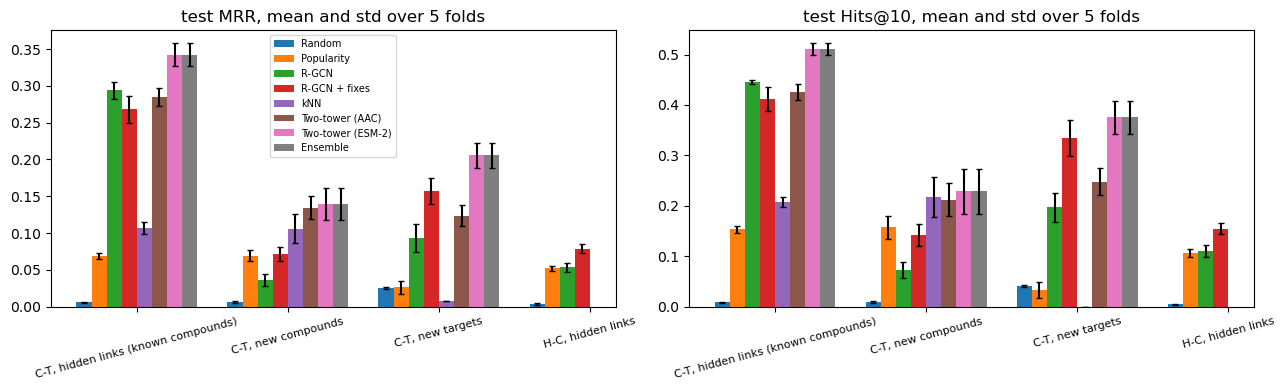

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ['MRR', 'Hits@10']):
    m = test.groupby(['task', 'model'])[metric].agg(['mean', 'std'])
    width = 0.8 / len(ORDER)
    for i, model in enumerate(ORDER):
        vals = [m.loc[(t, model), 'mean'] if (t, model) in m.index else np.nan for t in TASKS]
        errs = [m.loc[(t, model), 'std'] if (t, model) in m.index else 0 for t in TASKS]
        ax.bar(np.arange(len(TASKS)) + (i - len(ORDER) / 2 + 0.5) * width, vals, width, yerr=errs, capsize=2, label=model)
    ax.set_xticks(np.arange(len(TASKS)))
    ax.set_xticklabels([TASK_NAMES[t] for t in TASKS], rotation=15, fontsize=8)
    ax.set_title(f'test {metric}, mean and std over 5 folds')
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(RESULTS / 'test_metrics.png', dpi=110)
plt.show()